# Project :- Food Delivery Time Prediction


# Import Libraries 

In [86]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly as pl 
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV

# Scaling
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Pipeline
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Data Preprocessing 

`Data Import and Cleaning`

Load the dataset (Food_Delivery_Time_Prediction.csv)

In [53]:
df = pd.read_csv('/Users/shyamalkar/Desktop/ML_project/03_Food_Delivery_Time_Prediction/Food_Delivery_Time_Prediction (2).csv')


In [54]:
df.head()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [55]:
df.shape

(200, 15)

In [56]:
df.tail()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
195,ORD0196,"(17.910045, 81.56199)","(18.098924, 87.896124)",23.82,Cloudy,High,8,Medium,Night,Bike,4.7,4.0,50.39,1432.26,66.34
196,ORD0197,"(21.66459, 82.226635)","(16.892341, 80.554716)",6.09,Snowy,Medium,8,Low,Night,Bicycle,3.0,3.6,90.54,1720.25,40.27
197,ORD0198,"(14.575401, 82.55641)","(13.625369, 82.418092)",20.61,Snowy,High,4,Medium,Afternoon,Bike,2.9,3.4,73.20,1356.58,5.10
198,ORD0199,"(12.094497, 82.893369)","(19.135509, 86.659978)",24.06,Rainy,High,9,Low,Night,Car,3.9,4.8,53.94,354.39,85.25
199,ORD0200,"(19.360304, 84.132424)","(20.941636, 77.01334)",9.18,Snowy,Low,2,Low,Morning,Bike,4.6,3.2,78.58,323.73,48.91


In [57]:
df.dtypes

Order_ID                          str
Customer_Location                 str
Restaurant_Location               str
Distance                      float64
Weather_Conditions                str
Traffic_Conditions                str
Delivery_Person_Experience      int64
Order_Priority                    str
Order_Time                        str
Vehicle_Type                      str
Restaurant_Rating             float64
Customer_Rating               float64
Delivery_Time                 float64
Order_Cost                    float64
Tip_Amount                    float64
dtype: object

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    str    
 1   Customer_Location           200 non-null    str    
 2   Restaurant_Location         200 non-null    str    
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    str    
 5   Traffic_Conditions          200 non-null    str    
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    str    
 8   Order_Time                  200 non-null    str    
 9   Vehicle_Type                200 non-null    str    
 10  Restaurant_Rating           200 non-null    float64
 11  Customer_Rating             200 non-null    float64
 12  Delivery_Time               200 non-null    float64
 13  Order_Cost                  200 non-null    fl

In [59]:
df.describe()

,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,11.498050,5.250000,3.738500,3.686500,70.494950,1046.488700,46.616650
std,6.841755,2.745027,0.703021,0.697063,29.830694,548.568922,29.361706
min,0.520000,1.000000,2.500000,2.600000,15.230000,122.300000,1.240000
25%,6.090000,3.000000,3.200000,3.100000,46.997500,553.270000,21.602500
50%,10.265000,5.000000,3.800000,3.700000,72.775000,1035.950000,47.530000
75%,16.497500,8.000000,4.300000,4.300000,96.650000,1543.125000,70.245000
max,24.900000,10.000000,5.000000,5.000000,119.670000,1997.420000,99.740000


In [60]:
df.isnull().sum()

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

In [61]:
df = df.drop('Order_ID', axis=1)
df

,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,"(17.910045, 81.56199)","(18.098924, 87.896124)",23.82,Cloudy,High,8,Medium,Night,Bike,4.7,4.0,50.39,1432.26,66.34
196,"(21.66459, 82.226635)","(16.892341, 80.554716)",6.09,Snowy,Medium,8,Low,Night,Bicycle,3.0,3.6,90.54,1720.25,40.27
197,"(14.575401, 82.55641)","(13.625369, 82.418092)",20.61,Snowy,High,4,Medium,Afternoon,Bike,2.9,3.4,73.20,1356.58,5.10
198,"(12.094497, 82.893369)","(19.135509, 86.659978)",24.06,Rainy,High,9,Low,Night,Car,3.9,4.8,53.94,354.39,85.25


Encode categorical features (e.g., weather, traffic, and vehicle type) using LabelEncoder.


In [69]:
weather_encoder = LabelEncoder()
traffic_encoder = LabelEncoder()
vehicle_encoder = LabelEncoder()

df['Weather_Conditions'] = weather_encoder.fit_transform(df['Weather_Conditions'])

df['Traffic_Conditions'] = traffic_encoder.fit_transform(df['Traffic_Conditions'])

df['Vehicle_Type'] = vehicle_encoder.fit_transform(df['Vehicle_Type'])

df['Order_Priority'] = vehicle_encoder.fit_transform(df['Order_Priority'])

df['Order_Time'] = vehicle_encoder.fit_transform(df['Order_Time'])

Normalize continuous features such as distance and delivery time.


In [71]:
df['Delayed'] = (df['Delivery_Time'] > df['Delivery_Time'].median()).astype(int)

# Feature Engineering

Calculate the Geographic. distance between the customer and resturant using latitude and longitude (Haversine Formula)

In [73]:
import ast
import numpy as np

# Convert "(latitude, longitude)" text into two numbers
df[['Customer_Latitude', 'Customer_Longitude']] = df['Customer_Location'].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)

df[['Restaurant_Latitude', 'Restaurant_Longitude']] = df['Restaurant_Location'].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)


# Haversine formula
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometers

    # Convert degrees to radians
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    # Difference
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Haversine formula
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# Calculate geographical distance
df['Distance'] = haversine_distance(
    df['Customer_Latitude'],
    df['Customer_Longitude'],
    df['Restaurant_Latitude'],
    df['Restaurant_Longitude']
)

In [74]:
df[
    [
        'Customer_Location',
        'Restaurant_Location',
        'Distance'
    ]
].head()

,Customer_Location,Restaurant_Location,Distance
0,"(17.030479, 79.743077)","(12.358515, 85.100083)",775.651198
1,"(15.398319, 86.639122)","(14.174874, 77.025606)",1042.385597
2,"(15.687342, 83.888808)","(19.594748, 82.048482)",476.220706
3,"(20.415599, 78.046984)","(16.915906, 78.278698)",389.912629
4,"(14.786904, 78.706532)","(15.206038, 86.203182)",806.505886


Create binary categories based on delivery time (e.g., 1 for delayed and 0 for fast).


In [78]:
df.columns

Index(['Customer_Location', 'Restaurant_Location', 'Distance',
       'Weather_Conditions', 'Traffic_Conditions',
       'Delivery_Person_Experience', 'Order_Priority', 'Order_Time',
       'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time',
       'Order_Cost', 'Tip_Amount', 'Delayed', 'Customer_Latitude',
       'Customer_Longitude', 'Restaurant_Latitude', 'Restaurant_Longitude'],
      dtype='str')

In [79]:
df['Delayed'] = (df['Delivery_Time'] > df['Delivery_Time'].median()).astype(int)

In [82]:
df[['Delivery_Time', 'Delayed']].head()

,Delivery_Time,Delayed
0,26.22,0
1,62.61,0
2,48.43,0
3,111.63,1
4,32.38,0


# Phase 2: Classification using Naive Bayes, K-Nearest Neighbors, and Decision Tree


`Prepare X and y `

In [83]:
X = df[[
    'Distance',
    'Weather_Conditions',
    'Traffic_Conditions',
    'Delivery_Person_Experience',
    'Order_Priority',
    'Order_Time',
    'Vehicle_Type',
    'Restaurant_Rating',
    'Customer_Rating',
    'Order_Cost',
    'Tip_Amount'
]]

y = df['Delayed']

In [87]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 11)
y shape: (200,)


In [84]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Evaluation Function 

Instead of writing the same evaluation code three times, we'll create one reusable function.

In [88]:
def evaluate_model(model, X_test, y_test):
    
    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))

    print("\nConfusion Matrix:")
    print(cm)

    return y_pred

`Naive Bayes Classifier `

gaussian Naive Bayes, Which Naive Bayes, Which is Suitable when features are continuous / numerical . so i use standard scaler before it . 

In [89]:
nb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GaussianNB())
])

In [90]:
nb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Distance','Weather_Conditions','Traffic_Conditions',..., 'Customer_Rating','Order_Cost','Tip_Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [91]:
print("Gaussian Naive Bayes")

y_pred_nb = evaluate_model(
    nb_pipeline,
    X_test,
    y_test
)

Gaussian Naive Bayes
Accuracy : 0.525
Precision: 0.5263
Recall   : 0.5
F1-score : 0.5128

Confusion Matrix:
[[11  9]
 [10 10]]


`K-Nearest-Neighbors (KNN)`

`KNN is especially sensitive to feature scale. So standardscaler is importatn here.`

In [93]:
# First let's create the pipeline
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

`Knn Hyperparameter tuning `

The important hyperparameter is :

n_neighbors = k

we will test different k values using 5-Folds cross validation.

In [95]:
param_grid_knn = {
    'model__n_neighbors': range(1, 21)
}

In [96]:
# Now perform Grid Search
grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=5,
    scoring='accuracy'
)

grid_knn.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': range(1, 21)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during f

In [97]:
# Find the best k 
print("Best K:", grid_knn.best_params_['model__n_neighbors'])
print("Best CV Accuracy:", round(grid_knn.best_score_, 4))

Best K: 17
Best CV Accuracy: 0.5812


In [100]:
# Evaluate the best KNN

print("\nKNN")

y_pred_knn = evaluate_model(
    grid_knn.best_estimator_,
    X_test,
    y_test
)


KNN
Accuracy : 0.4
Precision: 0.4091
Recall   : 0.45
F1-score : 0.4286

Confusion Matrix:
[[ 7 13]
 [11  9]]


# Decision Tree:

Train a Decision Tree Classifier to model the classfication of delivery times 

In [102]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

Hyperparameter Tuning 

In [103]:
param_grid_dt = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 20]
}

In [104]:
grid_dt = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy'
)

grid_dt.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of info

In [105]:
print("Best Parameters:", grid_dt.best_params_)
print("Best CV Accuracy:", round(grid_dt.best_score_, 4))

Best Parameters: {'max_depth': 8, 'min_samples_split': 2}
Best CV Accuracy: 0.5438


Evaluation Metrics

In [106]:
print("\nDecision Tree")

y_pred_dt = evaluate_model(
    grid_dt.best_estimator_,
    X_test,
    y_test
)


Decision Tree
Accuracy : 0.475
Precision: 0.4815
Recall   : 0.65
F1-score : 0.5532

Confusion Matrix:
[[ 6 14]
 [ 7 13]]


# Reporting and Insights

`Model Comparison:`

Compare the performance of Naive Bayes, KNN, and Decision Tree classifiers using metrics such as accuracy, precision, recall, and F1-score.

In [108]:
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Gaussian Naive Bayes,0.525,0.5263,0.50,0.5128
1,KNN,0.400,0.4091,0.45,0.4286
2,Decision Tree,0.475,0.4815,0.65,0.5532


In [109]:
results.sort_values(
    by='F1-Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-Score
2,Decision Tree,0.475,0.4815,0.65,0.5532
0,Gaussian Naive Bayes,0.525,0.5263,0.50,0.5128
1,KNN,0.400,0.4091,0.45,0.4286


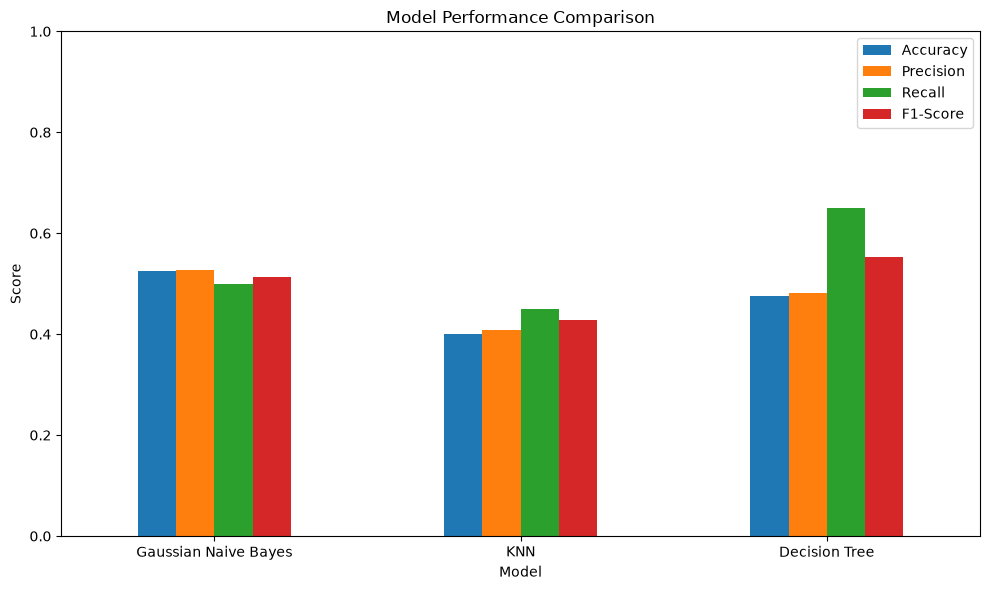

In [110]:
import matplotlib.pyplot as plt

results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

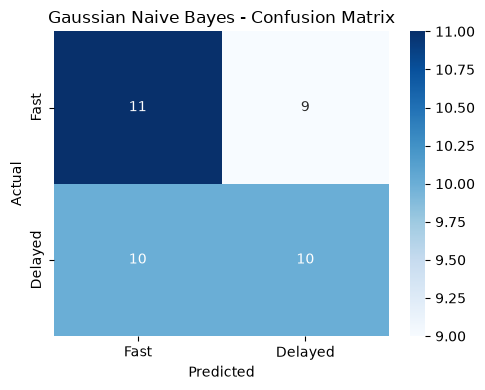

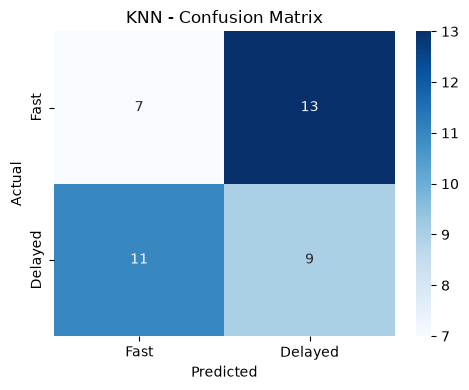

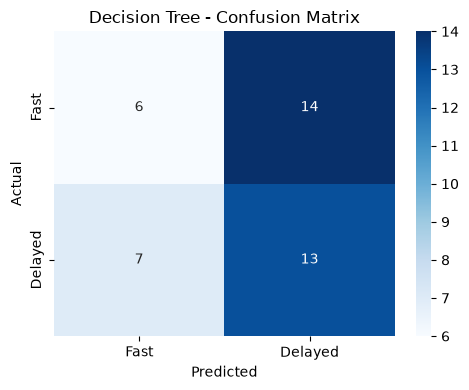

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    'Gaussian Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt
}

for model_name, predictions in models.items():

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Fast', 'Delayed'],
        yticklabels=['Fast', 'Delayed']
    )

    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Visualize the confusion matrix and ROC curves to analyze the classification results.


In [112]:
# Probability of class 1 = Delayed

y_prob_nb = nb_pipeline.predict_proba(X_test)[:, 1]

y_prob_knn = grid_knn.best_estimator_.predict_proba(X_test)[:, 1]

y_prob_dt = grid_dt.best_estimator_.predict_proba(X_test)[:, 1]

In [114]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

In [115]:
auc_nb = roc_auc_score(y_test, y_prob_nb)
auc_knn = roc_auc_score(y_test, y_prob_knn)
auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Naive Bayes AUC :", round(auc_nb, 4))
print("KNN AUC         :", round(auc_knn, 4))
print("Decision Tree AUC:", round(auc_dt, 4))

Naive Bayes AUC : 0.51
KNN AUC         : 0.3688
Decision Tree AUC: 0.4075


# plot ruc cruve

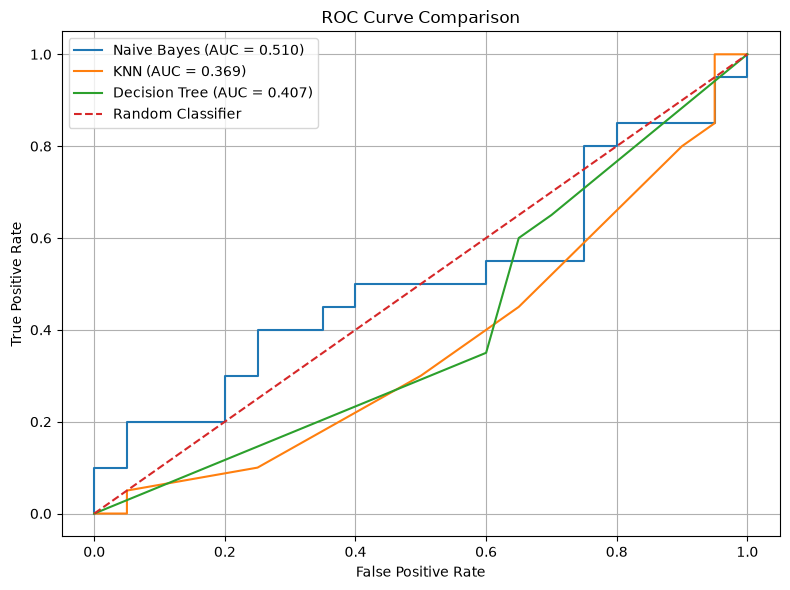

In [116]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f'Naive Bayes (AUC = {auc_nb:.3f})'
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f'KNN (AUC = {auc_knn:.3f})'
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {auc_dt:.3f})'
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Automatically identify the best model 

In [117]:
best_model = results.loc[
    results['F1-Score'].idxmax()
]

print("Best Model:", best_model['Model'])
print("Accuracy :", best_model['Accuracy'])
print("Precision:", best_model['Precision'])
print("Recall   :", best_model['Recall'])
print("F1-Score :", best_model['F1-Score'])

Best Model: Decision Tree
Accuracy : 0.475
Precision: 0.4815
Recall   : 0.65
F1-Score : 0.5532


# Summary 

### Final Report

This project developed a machine learning system to classify food deliveries as **Fast (0)** or **Delayed (1)**. Feature engineering included calculating geographical distance using the **Haversine formula** and creating a binary delivery-status target. Three classifiers—**Gaussian Naive Bayes, KNN, and Decision Tree**—were trained and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC. KNN and Decision Tree were tuned using cross-validation and hyperparameters. The best-performing model should be selected based on **F1-score and recall**, while Decision Tree is preferred when interpretability is important. These predictions can help food-delivery businesses identify potential delays and improve delivery planning.